# Assignment2

In [1]:
# NumPy: schnelle Array-Operationen; hier v. a. für die zufällige Permutation beim Train/Val-Split
import numpy as np
# pandas: komfortables Einlesen und Vorverarbeiten von Tabellen (CSV) mit benannten Spalten
import pandas as pd
# matplotlib: zum Plotten der Lernkurven (Accuracy pro Epoche)
import matplotlib.pyplot as plt
# PyTorch: Tensoren + automatisches Differenzieren (Autograd) für das Training
import torch
# torch.nn: fertige Bausteine für Netze (Layer, Aktivierungen, Loss-Funktionen)
import torch.nn as nn
# Dataset = Schnittstelle für eigene Datensätze, DataLoader = liefert daraus Mini-Batches (inkl. Shuffling)
from torch.utils.data import Dataset, DataLoader

# Fester Seed für den PyTorch-Zufallsgenerator: Gewichtsinitialisierung, Shuffling und Dropout
# werden dadurch bei jedem Lauf gleich -> Ergebnisse sind reproduzierbar und vergleichbar
torch.manual_seed(42)  # reproduzierbare Ergebnisse

## 1. Custom Dataset

In [2]:
# Eigene Klasse, die von torch.utils.data.Dataset erbt. Dadurch kann der DataLoader
# sie benutzen – er braucht nur __len__ (Anzahl Samples) und __getitem__ (ein Sample holen).
class TitanicDataSet(Dataset):
    """Titanic-Datensatz mit Vorverarbeitung und 80/20 Train/Val-Split."""

    # Numerische Spalten: haben sehr unterschiedliche Wertebereiche (Fare bis ~500, Parch 0–6),
    # deshalb werden sie später standardisiert, damit kein Feature das Training dominiert.
    NUMERIC = ["Pclass", "Age", "SibSp", "Parch", "Fare"]  # werden standardisiert
    # Kategorische Spalten: Text-Werte ("male", "S", ...) kann ein Netz nicht direkt verarbeiten,
    # deshalb One-Hot-Kodierung (eine 0/1-Spalte pro Kategorie, ohne künstliche Reihenfolge).
    CATEGORICAL = ["Sex", "Embarked"]  # werden one-hot-kodiert

    # train=True liefert den Trainingsteil, train=False den Validierungsteil.
    # val_split=0.2 -> 20 % Validierung; seed sorgt dafür, dass beide Instanzen denselben Split erzeugen.
    def __init__(self, csv_file, train=True, val_split=0.2, seed=42):
        # CSV als DataFrame einlesen (eine Zeile = ein Passagier)
        df = pd.read_csv(csv_file)
        # Nur die benötigten Spalten behalten. Name, Ticket, Cabin, PassengerId werden weggelassen,
        # weil sie kaum direkt nutzbar sind (Freitext / viele fehlende Werte / reine IDs).
        # .copy() verhindert pandas' SettingWithCopyWarning bei späteren Änderungen.
        df = df[self.NUMERIC + self.CATEGORICAL + ["Survived"]].copy()

        # Zufällige Reihenfolge aller Zeilenindizes. Eigener Generator mit festem Seed ->
        # Train- und Val-Instanz bekommen exakt dieselbe Permutation, also disjunkte Mengen.
        perm = np.random.default_rng(seed).permutation(len(df))
        # Anzahl Validierungs-Samples (z. B. 891 * 0.2 = 178)
        n_val = int(len(df) * val_split)
        # Die ersten n_val permutierten Indizes -> Validierung, der Rest -> Training
        train_idx, val_idx = perm[n_val:], perm[:n_val]
        # Nur die Trainingszeilen: daraus werden alle Statistiken (Median, Modus, Mittelwert, Std) berechnet
        train_df = df.iloc[train_idx]

        # Fehlende Altersangaben (~20 %) mit dem Median des TRAININGSsets füllen.
        # Median statt Mittelwert, weil er robust gegen Ausreißer ist. Nur Trainingsdaten benutzen,
        # damit keine Information aus dem Validierungsset ins Training "leakt" (Data Leakage).
        df["Age"] = df["Age"].fillna(train_df["Age"].median())
        # Die 2 fehlenden Einstiegshäfen mit dem häufigsten Wert (Modus) füllen –
        # für kategorische Daten ist der Modus die natürliche Wahl. [0], weil mode() eine Series liefert.
        df["Embarked"] = df["Embarked"].fillna(train_df["Embarked"].mode()[0])

        # Mittelwert und Standardabweichung der numerischen Spalten – wieder NUR aus den Trainingsdaten
        # (df.iloc statt train_df, weil Age inzwischen aufgefüllt wurde)
        mean = df.iloc[train_idx][self.NUMERIC].mean()
        std = df.iloc[train_idx][self.NUMERIC].std()
        # Standardisierung (z-Score): jedes Feature hat danach ~Mittelwert 0 und Std 1.
        # Das macht Gradienten für alle Gewichte ähnlich groß -> stabileres, schnelleres Training.
        df[self.NUMERIC] = (df[self.NUMERIC] - mean) / std

        # One-Hot-Kodierung: aus "Sex" werden Sex_female/Sex_male, aus "Embarked" Embarked_C/Q/S.
        # dtype=float, damit die Spalten direkt als float-Tensor nutzbar sind (statt bool).
        # Auf dem GANZEN df, damit Train und Val garantiert dieselben Spalten haben.
        df = pd.get_dummies(df, columns=self.CATEGORICAL, dtype=float)

        # Erst jetzt den gewünschten Teil auswählen (Train oder Val) – alle Vorverarbeitung ist identisch
        df = df.iloc[train_idx if train else val_idx]
        # Namen aller Eingabespalten merken (alles außer dem Label) – für D_in und zur Kontrolle
        self.feature_names = [c for c in df.columns if c != "Survived"]
        # Features als float32-Tensor der Form (N, 10); float32 ist der Standard-Datentyp der nn-Layer
        self.X = torch.tensor(df[self.feature_names].values, dtype=torch.float32)
        # Labels als float32 (BCELoss erwartet Floats, keine Ints). unsqueeze(1) macht aus (N,) -> (N, 1),
        # damit die Form exakt zur Netzausgabe (N, 1) passt und BCELoss nicht falsch broadcastet.
        self.y = torch.tensor(df["Survived"].values, dtype=torch.float32).unsqueeze(1)  # Form (N, 1) für BCE

    # Vom DataLoader benötigt: wie viele Samples gibt es (um Batches/Epochen zu bestimmen)
    def __len__(self):
        return len(self.y)

    # Vom DataLoader benötigt: gibt ein Sample (Features, Label) für Index idx zurück.
    # Der DataLoader ruft das für mehrere idx auf und stapelt die Ergebnisse zu einem Batch.
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [3]:
# Trainings-Datensatz (80 % = 713 Passagiere) erzeugen
titanic_train = TitanicDataSet('titanic.csv', train=True)
# Validierungs-Datensatz (20 % = 178 Passagiere) – gleicher Seed, also disjunkt zum Training
titanic_val = TitanicDataSet('titanic.csv', train=False)

# Kontrolle: stimmen die Größen des Splits?
print(len(titanic_train), len(titanic_val))
# Kontrolle: welche Features sind nach der One-Hot-Kodierung entstanden?
print(titanic_train.feature_names)
# Kontrolle: ein Beispiel-Sample ansehen (standardisierte Werte, Label als (1,)-Tensor)
print(titanic_train[0])

713 178
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
(tensor([ 0.8254, -0.1614, -0.4823, -0.4682, -0.4902,  0.0000,  1.0000,  0.0000,
         0.0000,  1.0000]), tensor([1.]))


## 2. Netz mit einer Hidden Layer (Größe 3), BCE-Loss, Batchgröße 16

In [4]:
# DataLoader für das Training: Mini-Batches à 16 Samples (Aufgabenvorgabe).
# shuffle=True mischt die Daten jede Epoche neu -> Batches sind nicht immer gleich,
# das verhindert, dass das Netz die Reihenfolge lernt, und verbessert die Generalisierung.
train_loader = DataLoader(titanic_train, batch_size=16, shuffle=True)
# Für die Validierung kein Shuffling nötig – es wird nur ausgewertet, nicht gelernt
val_loader = DataLoader(titanic_val, batch_size=16, shuffle=False)

# Anzahl Eingabeneuronen = Anzahl Features; aus dem Datensatz gelesen statt hart codiert
D_in = len(titanic_train.feature_names)  # 10 Eingabefeatures


# Netze in PyTorch erben von nn.Module: dadurch werden Parameter automatisch registriert
# (model.parameters()) und train()/eval() funktionieren.
class SimpleNet(nn.Module):
    """Eine Hidden Layer mit 3 Neuronen, Sigmoid am Ausgang."""

    # H=3: Größe der Hidden Layer laut Aufgabenstellung
    def __init__(self, D_in, H=3):
        # Konstruktor von nn.Module aufrufen – Pflicht, sonst funktioniert die Parameterverwaltung nicht
        super().__init__()
        # nn.Sequential führt die Layer nacheinander aus – kompakter als jeden Layer einzeln anzulegen
        self.net = nn.Sequential(
            # Vollverbundene Schicht: 10 Eingaben -> 3 Hidden-Neuronen (y = Wx + b)
            nn.Linear(D_in, H),
            # Nichtlinearität: ohne sie wären zwei Linear-Layer nur eine einzige lineare Abbildung.
            # ReLU ist einfach, schnell und hat kein Sättigungsproblem für positive Werte.
            nn.ReLU(),
            # Ausgabeschicht: 3 Hidden-Neuronen -> 1 Ausgabe (binäre Klassifikation: überlebt ja/nein)
            nn.Linear(H, 1),
            # Sigmoid quetscht die Ausgabe nach (0, 1) -> interpretierbar als P(Survived=1).
            # Nötig, weil nn.BCELoss Wahrscheinlichkeiten erwartet.
            nn.Sigmoid(),
        )

    # Forward-Pass: wie aus einer Eingabe x die Ausgabe berechnet wird. Backward macht Autograd automatisch.
    def forward(self, x):
        return self.net(x)


# Binary Cross Entropy: Standard-Loss für binäre Klassifikation mit Wahrscheinlichkeitsausgabe.
# Bestraft sichere Fehlvorhersagen stark (−log p) und passt mathematisch zur Sigmoid-Ausgabe.
criterion = nn.BCELoss()


# Eine Epoche = einmal über alle Trainingsdaten iterieren
def train_epoch(model, optimizer):  # trainiert eine Epoche
    # Trainingsmodus: aktiviert z. B. Dropout (wichtig für DeepNet in Aufgabe 6)
    model.train()
    # Der DataLoader liefert Batches: data hat Form (16, 10), target hat Form (16, 1)
    for data, target in train_loader:
        # Gradienten aus dem vorherigen Schritt löschen – PyTorch summiert sie sonst auf
        optimizer.zero_grad()
        # Forward-Pass + Loss zwischen Vorhersage und echtem Label berechnen
        loss = criterion(model(data), target)
        # Backpropagation: Gradienten des Loss bzgl. aller Gewichte berechnen
        loss.backward()
        # Gewichte anhand der Gradienten aktualisieren (hier mit Adam)
        optimizer.step()


# Bewertet ein Modell auf einem beliebigen DataLoader (Train oder Val), ohne zu lernen
def evaluate(model, loader):  # liefert (Loss, Accuracy) auf einem Datensatz
    # Evaluationsmodus: Dropout aus, damit die Auswertung deterministisch und vollständig ist
    model.eval()  # Evaluationsmodus (Dropout aus)
    # Akkumulatoren für Gesamt-Loss und Anzahl richtiger Vorhersagen
    total_loss, correct = 0.0, 0
    # Keine Gradienten berechnen: spart Speicher und Zeit, wir wollen hier nichts lernen
    with torch.no_grad():
        for data, target in loader:
            # Vorhersagen (Wahrscheinlichkeiten) für den Batch
            output = model(data)
            # criterion liefert den MITTLEREN Loss des Batches; * len(data) ergibt die Summe.
            # So zählt auch der letzte, evtl. kleinere Batch korrekt gewichtet.
            # .item() wandelt den 1-Element-Tensor in eine Python-Zahl um.
            total_loss += criterion(output, target).item() * len(data)
            # Wahrscheinlichkeit > 0.5 -> Klasse 1 (überlebt), sonst 0. Mit Label vergleichen und Treffer zählen
            correct += ((output > 0.5).float() == target).sum().item()  # Schwelle 0.5
    # Gesamtanzahl Samples im Datensatz (nicht Anzahl Batches!)
    n = len(loader.dataset)
    # Mittlerer Loss pro Sample und Anteil richtiger Vorhersagen (Accuracy)
    return total_loss / n, correct / n


# Kompletter Trainingslauf; gibt das trainierte Modell und den Verlauf der Metriken zurück
def run_training(model, n_epochs, lr):
    # Adam-Optimizer: passt die Lernrate pro Parameter adaptiv an -> konvergiert meist schneller
    # und robuster als einfaches SGD. model.parameters() übergibt alle trainierbaren Gewichte.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # Verlauf pro Epoche speichern, um später die Lernkurven plotten zu können
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    # Epochen ab 1 zählen (lesbarer für die Ausgabe)
    for epoch in range(1, n_epochs + 1):
        # Eine Epoche lernen
        train_epoch(model, optimizer)
        # Danach auf Trainingsdaten auswerten (im eval-Modus, also ohne Dropout -> fairer Vergleich mit Val)
        tr_loss, tr_acc = evaluate(model, train_loader)
        # Auf Validierungsdaten auswerten -> zeigt, wie gut das Modell auf ungesehene Daten generalisiert
        va_loss, va_acc = evaluate(model, val_loader)
        # Werte an den Verlauf anhängen
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        # Nur in Epoche 1 und dann 10-mal insgesamt ausgeben, damit die Ausgabe übersichtlich bleibt
        if epoch == 1 or epoch % (n_epochs // 10) == 0:
            print("Epoch {:3d}/{}  train loss {:.4f} acc {:.3f} | val loss {:.4f} acc {:.3f}".format(
                epoch, n_epochs, tr_loss, tr_acc, va_loss, va_acc))
    # Modell und Verlauf zurückgeben
    return model, history

In [5]:
# Seed direkt vor dem Erzeugen des Modells neu setzen -> gleiche Startgewichte bei jedem Ausführen der Zelle
torch.manual_seed(42)
# Kleines Netz (1 Hidden Layer, 3 Neuronen) 100 Epochen mit Lernrate 0.01 trainieren.
# Für ein so kleines Netz ist eine relativ große Lernrate unproblematisch und konvergiert schnell.
model_small, hist_small = run_training(SimpleNet(D_in, H=3), n_epochs=100, lr=0.01)

Epoch   1/100  train loss 0.5298 acc 0.781 | val loss 0.5375 acc 0.736
Epoch  10/100  train loss 0.4100 acc 0.822 | val loss 0.4269 acc 0.803
Epoch  20/100  train loss 0.4011 acc 0.833 | val loss 0.4549 acc 0.815
Epoch  30/100  train loss 0.3963 acc 0.830 | val loss 0.4578 acc 0.792
Epoch  40/100  train loss 0.3968 acc 0.829 | val loss 0.4703 acc 0.803
Epoch  50/100  train loss 0.3994 acc 0.822 | val loss 0.4490 acc 0.792
Epoch  60/100  train loss 0.3936 acc 0.832 | val loss 0.4602 acc 0.809
Epoch  70/100  train loss 0.3934 acc 0.833 | val loss 0.4636 acc 0.792
Epoch  80/100  train loss 0.3932 acc 0.832 | val loss 0.4631 acc 0.815
Epoch  90/100  train loss 0.3941 acc 0.837 | val loss 0.4717 acc 0.803
Epoch 100/100  train loss 0.3908 acc 0.837 | val loss 0.4568 acc 0.803


## 3. Validierungs-Accuracy

In [6]:
# Trainiertes kleines Netz auf dem Validierungsset auswerten (Loss wird hier nicht weiter benötigt)
val_loss, val_acc = evaluate(model_small, val_loader)
# Accuracy in Prozent ausgeben, zusammen mit der Anzahl der Validierungs-Passagiere als Kontext
print("Validation accuracy: {:.2f}% ({} Passagiere)".format(100 * val_acc, len(titanic_val)))

Validation accuracy: 80.34% (178 Passagiere)


## 4. Plot: Training- vs. Validierungs-Accuracy

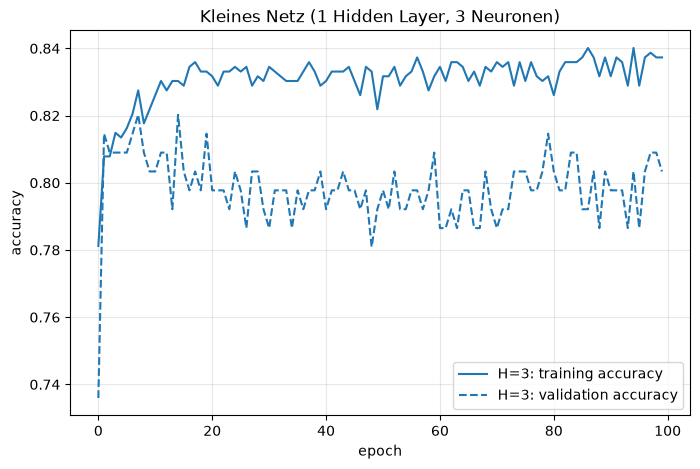

In [7]:
# Wiederverwendbare Plot-Funktion: mehrere Trainingsläufe in einem Diagramm vergleichen (für Aufgaben 4–6)
def plot_history(histories, title):
    """histories: dict label -> history. Trainings- und Validierungs-Accuracy pro Epoche."""
    # Neue Figur mit einer Achse; 8x5 Zoll ist gut lesbar
    fig, ax = plt.subplots(figsize=(8, 5))
    # Für jeden Lauf (z. B. "H=3", "3x256") die Kurven zeichnen
    for label, h in histories.items():
        # Trainings-Accuracy als durchgezogene Linie. Das Komma entpackt die Liste, die plot() zurückgibt,
        # damit wir die Linie (und ihre Farbe) weiterverwenden können.
        line, = ax.plot(h["train_acc"], label=f"{label}: training accuracy")
        # Validierungs-Accuracy gestrichelt in DERSELBEN Farbe -> man sieht sofort, welche Kurven zusammengehören
        ax.plot(h["val_acc"], linestyle="--", color=line.get_color(), label=f"{label}: validation accuracy")
    # Achsenbeschriftungen und Titel
    ax.set_xlabel("epoch")
    ax.set_ylabel("accuracy")
    ax.set_title(title)
    # Dezentes Gitter (alpha=0.3) erleichtert das Ablesen, ohne die Kurven zu überdecken
    ax.grid(alpha=0.3)
    # Legende mit den oben gesetzten Labels
    ax.legend()
    # Plot anzeigen
    plt.show()


# Lernkurven des kleinen Netzes: Train- und Val-Accuracy liegen nah beieinander -> kein Overfitting
plot_history({"H=3": hist_small}, "Kleines Netz (1 Hidden Layer, 3 Neuronen)")

## 5. Komplexeres Netz – Overfitting

Epoch   1/300  train loss 0.4366 acc 0.819 | val loss 0.4596 acc 0.798
Epoch  30/300  train loss 0.3011 acc 0.857 | val loss 0.6064 acc 0.775
Epoch  60/300  train loss 0.2402 acc 0.900 | val loss 0.6750 acc 0.792
Epoch  90/300  train loss 0.2241 acc 0.909 | val loss 0.8959 acc 0.803
Epoch 120/300  train loss 0.2040 acc 0.917 | val loss 2.0258 acc 0.798
Epoch 150/300  train loss 0.1896 acc 0.931 | val loss 2.1040 acc 0.809
Epoch 180/300  train loss 0.1704 acc 0.935 | val loss 2.3127 acc 0.781
Epoch 210/300  train loss 0.1584 acc 0.941 | val loss 2.8058 acc 0.775
Epoch 240/300  train loss 0.1474 acc 0.940 | val loss 2.8714 acc 0.787
Epoch 270/300  train loss 0.1417 acc 0.944 | val loss 2.8422 acc 0.775
Epoch 300/300  train loss 0.1416 acc 0.942 | val loss 3.0003 acc 0.770


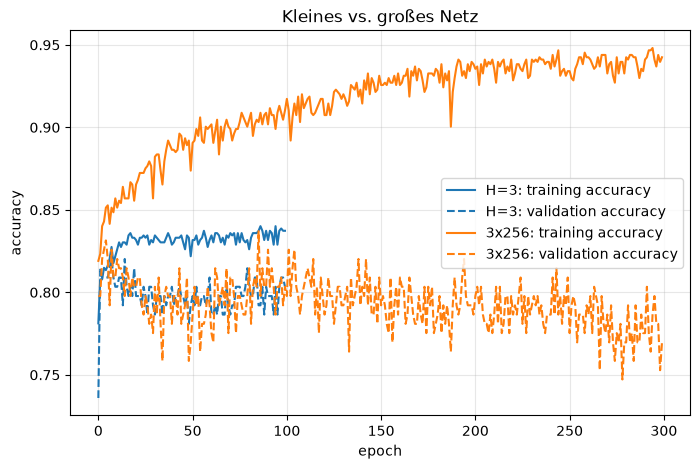

In [8]:
# Großes, flexibel konfigurierbares Netz – soll absichtlich overfitten (Aufgabe 5)
# und in Aufgabe 6 mit Dropout regularisiert werden.
class DeepNet(nn.Module):
    """Mehrere große Hidden Layers, optional mit Dropout nach jeder Hidden Layer."""

    # hidden: Größen der Hidden Layers (Standard 3x256 -> sehr viele Parameter für nur 713 Samples).
    # p_dropout=0.0 heißt: standardmäßig kein Dropout, so kann dieselbe Klasse für beide Aufgaben dienen.
    def __init__(self, D_in, hidden=(256, 256, 256), p_dropout=0.0):
        # Konstruktor von nn.Module aufrufen
        super().__init__()
        # layers sammelt die Bausteine; prev ist die Ausgabegröße des vorherigen Layers (Start: Eingabe)
        layers, prev = [], D_in
        # Für jede Hidden-Layer-Größe einen Block erzeugen -> Netzaufbau per Parameter statt hart codiert
        for h in hidden:
            # Linear-Layer von prev -> h Neuronen, gefolgt von ReLU als Nichtlinearität
            layers += [nn.Linear(prev, h), nn.ReLU()]
            # Optional Dropout: schaltet im Training zufällig Neuronen ab (Anteil p_dropout).
            # Das Netz kann sich so nicht auf einzelne Neuronen verlassen -> weniger Auswendiglernen.
            if p_dropout > 0:
                layers.append(nn.Dropout(p_dropout))
            # Die Ausgabe dieses Layers ist die Eingabe des nächsten
            prev = h
        # Ausgabeschicht wie beim kleinen Netz: ein Neuron + Sigmoid für die Wahrscheinlichkeit
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        # Liste in ein Sequential packen; * entpackt die Liste in einzelne Argumente
        self.net = nn.Sequential(*layers)

    # Forward-Pass: Daten durch alle Layer schicken
    def forward(self, x):
        return self.net(x)


# Seed setzen -> reproduzierbare Initialisierung des großen Netzes
torch.manual_seed(42)
# Großes Netz 300 Epochen trainieren. Kleinere Lernrate (0.001, Adam-Standard), weil große Netze
# bei hohen Lernraten instabil werden. Viele Epochen, damit das Overfitting deutlich sichtbar wird.
model_big, hist_big = run_training(DeepNet(D_in), n_epochs=300, lr=0.001)
# Vergleich: Beim großen Netz steigt die Train-Accuracy weiter, die Val-Accuracy stagniert/fällt -> Overfitting
plot_history({"H=3": hist_small, "3x256": hist_big}, "Kleines vs. großes Netz")

## 6. Dropout gegen Overfitting

Epoch   1/300  train loss 0.4847 acc 0.790 | val loss 0.5039 acc 0.753
Epoch  30/300  train loss 0.3518 acc 0.844 | val loss 0.4508 acc 0.809
Epoch  60/300  train loss 0.3196 acc 0.864 | val loss 0.4654 acc 0.809
Epoch  90/300  train loss 0.3042 acc 0.871 | val loss 0.4932 acc 0.809
Epoch 120/300  train loss 0.2852 acc 0.875 | val loss 0.5455 acc 0.820
Epoch 150/300  train loss 0.2785 acc 0.877 | val loss 0.5715 acc 0.809
Epoch 180/300  train loss 0.2730 acc 0.884 | val loss 0.5856 acc 0.820
Epoch 210/300  train loss 0.2647 acc 0.889 | val loss 0.6267 acc 0.798
Epoch 240/300  train loss 0.2535 acc 0.888 | val loss 0.6900 acc 0.815
Epoch 270/300  train loss 0.2512 acc 0.888 | val loss 0.6883 acc 0.803
Epoch 300/300  train loss 0.2528 acc 0.891 | val loss 0.6719 acc 0.820


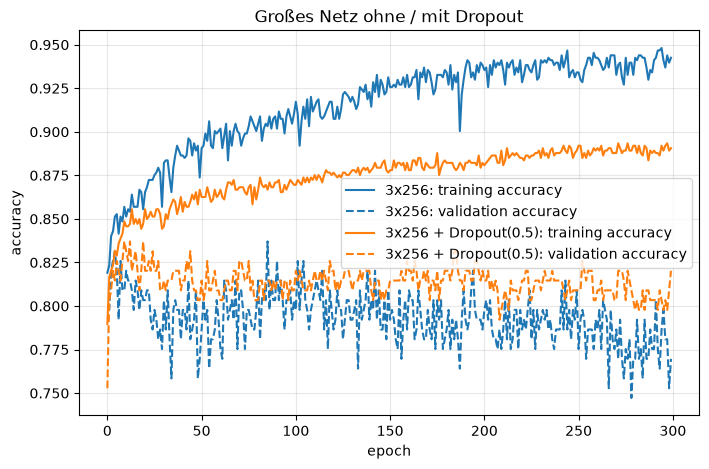

H=3                final train acc 0.837 | final val acc 0.803 | best val acc 0.820
3x256              final train acc 0.942 | final val acc 0.770 | best val acc 0.837
3x256 + Dropout    final train acc 0.891 | final val acc 0.820 | best val acc 0.837


In [10]:
# Seed setzen -> gleiche Startbedingungen wie beim großen Netz ohne Dropout (fairer Vergleich)
torch.manual_seed(42)
# Gleiche Architektur und Hyperparameter wie oben, nur mit Dropout p=0.5 nach jeder Hidden Layer.
# 0.5 ist ein klassischer Wert für Hidden Layers (aus dem ursprünglichen Dropout-Paper).
model_drop, hist_drop = run_training(DeepNet(D_in, p_dropout=0.5), n_epochs=300, lr=0.001)
# Lernkurven ohne vs. mit Dropout: mit Dropout liegen Train- und Val-Accuracy näher beieinander
plot_history({"3x256": hist_big, "3x256 + Dropout(0.5)": hist_drop}, "Großes Netz ohne / mit Dropout")

# Zusammenfassende Tabelle aller drei Modelle
for name, h in [("H=3", hist_small), ("3x256", hist_big), ("3x256 + Dropout", hist_drop)]:
    # Finale Train-/Val-Accuracy (letzte Epoche, [-1]) und beste Val-Accuracy über alle Epochen.
    # Eine große Lücke zwischen train und val zeigt Overfitting an.
    # {:18s} = linksbündig auf 18 Zeichen aufgefüllt, damit die Spalten untereinander stehen.
    print("{:18s} final train acc {:.3f} | final val acc {:.3f} | best val acc {:.3f}".format(
        name, h["train_acc"][-1], h["val_acc"][-1], max(h["val_acc"])))